In [2]:
import pandas as pd

df = pd.read_csv('D:\FYP\Code\Dataset\downsampled_data.csv')

Amplitude data only.

They ommitted data preprocessing.

CSI sampling frequency is 100 Hz. But frequency in our downsampled data is 25 Hz.

In [22]:
# Amplitude data only.
X1 = df.iloc[:, 2:66]
X2 = df.iloc[:, 130:194]
X = pd.concat([X1, X2], axis=1)

Y = df.iloc[:, -1]

In [23]:
X

,amplitude1_1,amplitude2_1,amplitude3_1,amplitude4_1,amplitude5_1,amplitude6_1,amplitude7_1,amplitude8_1,amplitude9_1,amplitude10_1,...,amplitude55_2,amplitude56_2,amplitude57_2,amplitude58_2,amplitude59_2,amplitude60_2,amplitude61_2,amplitude62_2,amplitude63_2,amplitude64_2
0,118.726577,5.0,29.732137,31.953091,33.241540,33.105891,32.249031,30.805844,29.068884,26.870058,...,-2.089942,-2.062606,-2.034444,-2.003204,-2.000559,-2.034444,-2.134113,-2.253113,-2.459276,-2.593043
1,118.726577,5.0,28.600699,30.000000,31.064449,30.886890,29.546573,28.792360,26.925824,24.331050,...,-1.604117,-1.570796,-1.536327,-1.496857,-1.490966,-1.527345,-1.616220,-1.719686,-1.923787,-2.013171
2,118.726577,5.0,29.529646,30.886890,32.756679,33.015148,31.890437,31.112698,28.425341,25.806976,...,2.790148,2.819842,2.840672,2.863293,2.878598,2.846152,2.718739,2.634494,2.427502,2.253113
3,118.726577,5.0,29.000000,31.000000,32.062439,32.249031,31.780497,30.364453,28.231188,25.942244,...,0.739975,0.762147,0.809784,0.811034,0.840897,0.815692,0.718830,0.574305,0.418224,0.244979
4,118.726577,5.0,28.861739,30.805844,31.575307,32.249031,32.015621,30.066593,28.284271,25.709920,...,2.089942,2.105751,2.167973,2.158799,2.169215,2.147172,2.055274,1.923787,1.719686,1.570796
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
116570,118.726577,5.0,7.280110,9.848858,11.661904,13.892444,16.124515,17.000000,17.464249,17.464249,...,-0.404892,-0.358771,-0.339293,-0.270947,-0.218669,-0.231091,-0.185348,-0.211093,-0.266252,-0.321751
116571,118.726577,5.0,13.000000,18.248288,24.083189,28.160256,31.256999,33.376639,33.734256,33.955854,...,0.374334,0.424194,0.463648,0.512389,0.535811,0.564569,0.588003,0.607802,0.540420,0.512389
116572,118.726577,5.0,13.038405,18.027756,24.041631,28.160256,31.320920,32.572995,34.176015,34.014703,...,0.478352,0.489957,0.526066,0.572966,0.632749,0.665969,0.679414,0.664046,0.610726,0.531724
116573,118.726577,5.0,11.180340,16.124515,22.022716,26.019224,29.017236,31.064449,32.249031,32.388269,...,-2.809533,-2.782822,-2.740364,-2.690140,-2.642246,-2.615526,-2.611377,-2.618314,-2.659079,-2.723368


In [24]:
Y

0         4
1         4
2         4
3         4
4         4
         ..
116570    0
116571    0
116572    0
116573    0
116574    0
Name: activity, Length: 116575, dtype: int64

### Feature extraction

They proposed the mean and variance of CSI amplitude to be a couple of good indicators for intrusion detection. Denote the feature couple as F[α, β], where α represents the mean and β represents the variance of CSI amplitude respectively.

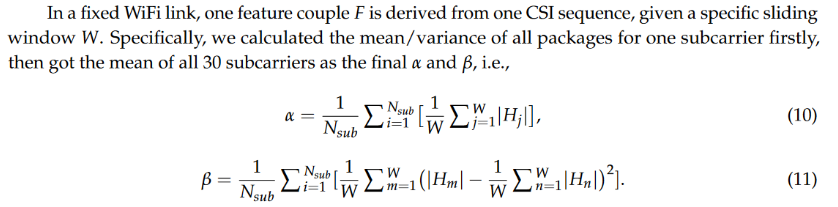

In [45]:
alpha = 0   # Alpha represents the mean of amplitude data in a window.
beta = 0    # Beta represents the varience of amplitude data in a window.

# In a sliding window of 25 samples, calculate the mean/variance of all packages for one subcarrier firstly, 
# then get the mean of all 64*2 subcarriers as the final α and β

w_index =  0    # Index of the window
# Window size = 25 samples; Considering 1 second of data

# for i in range(0, len(X), 25):
for i in range(0, 100, 25):
    w_index += 1
    window = X.iloc[i:i+25]
    # print(window)
    alpha = window.mean().mean()
    beta = window.var().mean()
    print('Window:', w_index, 'Mean:', alpha, 'Variance:', beta)

for window in range(0, len(X), 25):
    sum_amp_means = 0
    sum_amp_variences = 0
    for subcarrier in range(0, 64*2):
        sum_subcarrier_amplitudes = 0
        for i in range(window, window + 25):
            cell_value = X.iloc[i, subcarrier]
            sum_subcarrier_amplitudes += cell_value
            # sum_subcarrier_means += X.iloc[window, subcarrier].mean()
            # sum_subcarrier_variences += X.iloc[window, subcarrier].var()
        subcarrier_amp_mean = sum_subcarrier_amplitudes/25
        sum_amp_means += subcarrier_amp_mean

        sum_subcarrier_varience = 0
        for j in range (window, window +25):
            cell_value = X.iloc[j, subcarrier]
            sum_subcarrier_varience += (cell_value - subcarrier_amp_mean)**2
        subcarrier_amp_varience = sum_subcarrier_varience/25
        sum_amp_variences += subcarrier_amp_varience
        
        
    alpha = sum_amp_means/(64*2)
    beta = sum_amp_variences/(64*2)
    print('Alpha:', alpha, 'Beta:', beta)


Window: 1 Mean: 9.293428302496437 Variance: 3.091090673641717
Window: 2 Mean: 9.338530019660439 Variance: 3.138108266226241
Window: 3 Mean: 9.38321617743281 Variance: 2.7824011482993516
Window: 4 Mean: 9.57423768734613 Variance: 2.00367511593993
Alpha: 9.293428302496435 Beta: 2.9674470466960488
Alpha: 9.338530019660434 Beta: 3.0125839355771924
Alpha: 9.38321617743281 Beta: 2.6711051023673784
Alpha: 9.574237687346134 Beta: 1.923528111302333


In [25]:
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(X, Y, test_size=0.2, random_state=42)

In [26]:
from sklearn import svm

model = svm.SVC(C = 10 , gamma = 'auto' , kernel = 'linear', max_iter = 1)

model.fit(X_train, y_train)

c:\Python311\Lib\site-packages\sklearn\svm\_base.py:297: ConvergenceWarning: Solver terminated early (max_iter=1).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(


SVC(C=10, gamma='auto', kernel='linear', max_iter=1)

In [28]:
y_train

90690     0
17096     5
74933     0
7029      4
78050     0
         ..
76820     0
110268    4
103694    0
860       4
15795     0
Name: activity, Length: 93260, dtype: int64

In [29]:
from sklearn import metrics

accuracy = metrics.accuracy_score(y_pred, y_val)
print("Validation Accuracy:", accuracy)

Validation Accuracy: 0.23439845592965902


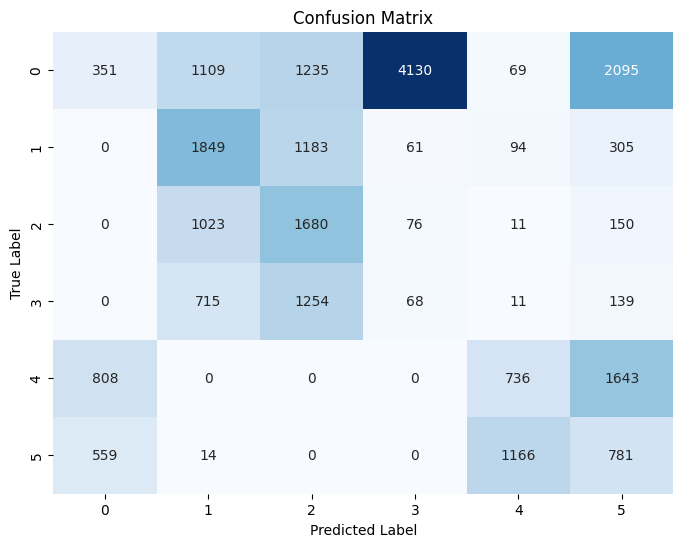

In [30]:
from sklearn.metrics import confusion_matrix
from matplotlib import pyplot as plt
import seaborn as sns

# Generate the confusion matrix
cm = confusion_matrix(y_val, y_pred)

# Plot the confusion matrix using seaborn heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False)
plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

In [31]:
from sklearn.metrics import precision_score, recall_score, f1_score

# Assuming you have true labels (y_actual) and predicted labels (y_pred)
# For each class (0, 1, 2, 3), calculate precision, recall, and F1 score
precision = precision_score(y_val, y_pred, average=None)
recall = recall_score(y_val, y_pred, average=None)
f1 = f1_score(y_val, y_pred, average=None)

# Print results for each class
for class_label in range(6):
    print(f"Class {class_label}:")
    print(f"Precision: {precision[class_label]:.4f}")
    print(f"Recall: {recall[class_label]:.4f}")
    print(f"F1 Score: {f1[class_label]:.4f}\n")


Class 0:
Precision: 0.2043
Recall: 0.0390
F1 Score: 0.0656

Class 1:
Precision: 0.3926
Recall: 0.5295
F1 Score: 0.4509

Class 2:
Precision: 0.3139
Recall: 0.5714
F1 Score: 0.4052

Class 3:
Precision: 0.0157
Recall: 0.0311
F1 Score: 0.0209

Class 4:
Precision: 0.3527
Recall: 0.2309
F1 Score: 0.2791

Class 5:
Precision: 0.1527
Recall: 0.3099
F1 Score: 0.2046



# Label Mapping


In [58]:
def predictionMapping(prediction):
	if prediction == 0 or prediction == 4:
		return 0
	elif prediction == 5:
		return 1
	else:
		return 2

# Night Time


In [41]:
for i in range (len(y_pred)):
	y_pred[i] = predictionMapping(y_pred[i])

y_val = y_val.apply(predictionMapping)

In [42]:
from sklearn import metrics

accuracy = metrics.accuracy_score(y_pred, y_val)
print("Validation Accuracy:", accuracy)

Validation Accuracy: 0.6195069667738478


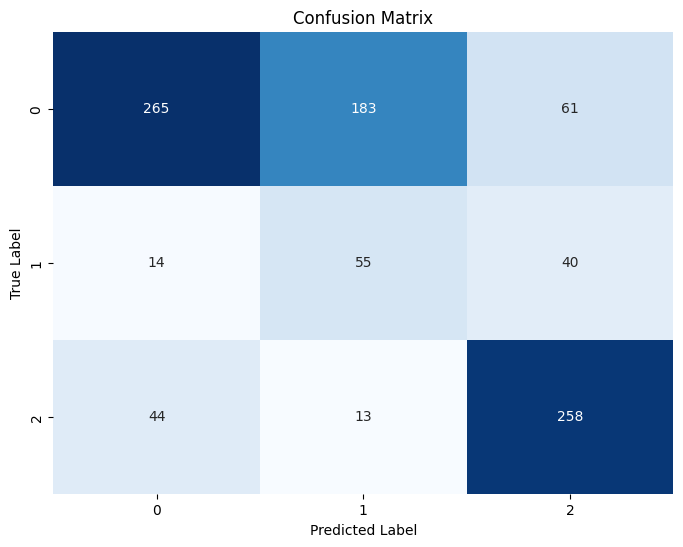

In [43]:
from sklearn.metrics import confusion_matrix
from matplotlib import pyplot as plt
import seaborn as sns

# Generate the confusion matrix
cm = confusion_matrix(y_val, y_pred)

# Plot the confusion matrix using seaborn heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False)
plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

In [44]:
from sklearn.metrics import f1_score

f1 = f1_score(y_val, y_pred, average='weighted')
print(f"F1 Score: {f1:.4f}")

F1 Score: 0.6417


In [45]:
from sklearn.metrics import precision_score, recall_score, f1_score

# Assuming you have true labels (y_actual) and predicted labels (y_pred)
# For each class (0, 1, 2, 3), calculate precision, recall, and F1 score
precision = precision_score(y_val, y_pred, average=None)
recall = recall_score(y_val, y_pred, average=None)
f1 = f1_score(y_val, y_pred, average=None)

# Print results for each class
for class_label in range(3):
    print(f"Class {class_label}:")
    print(f"Precision: {precision[class_label]:.4f}")
    print(f"Recall: {recall[class_label]:.4f}")
    print(f"F1 Score: {f1[class_label]:.4f}\n")


Class 0:
Precision: 0.8204
Recall: 0.5206
F1 Score: 0.6370

Class 1:
Precision: 0.2191
Recall: 0.5046
F1 Score: 0.3056

Class 2:
Precision: 0.7187
Recall: 0.8190
F1 Score: 0.7656



# Run only upper part until label mapping


In [72]:
night_y_val = []
night_y_pred = []

for i in range (len(y_pred)):
	if y_val.iloc[i] != 5:
		night_y_val.append(predictionMapping(y_val.iloc[i]))
		if y_pred[i] == 5:
			night_y_pred.append(predictionMapping(0))
		else:
			night_y_pred.append(predictionMapping(y_pred[i]))





In [73]:
from sklearn import metrics

accuracy = metrics.accuracy_score(night_y_pred, night_y_val)
print("Validation Accuracy:", accuracy)

Validation Accuracy: 0.8567961165048543


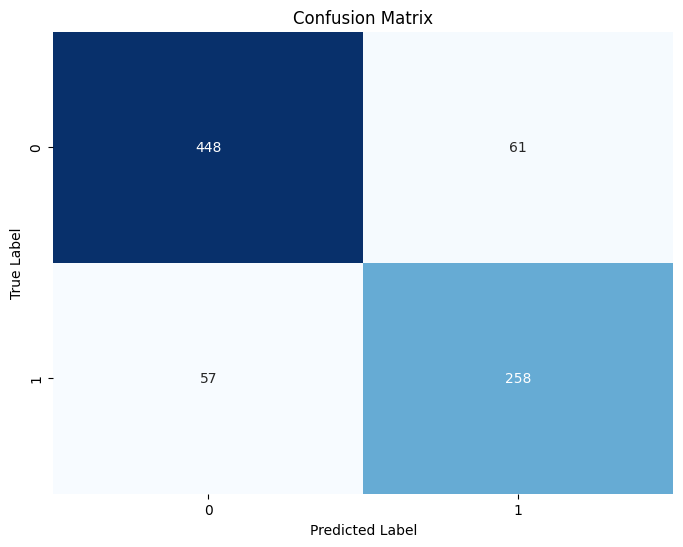

In [74]:
from sklearn.metrics import confusion_matrix
from matplotlib import pyplot as plt
import seaborn as sns

# Generate the confusion matrix
cm = confusion_matrix(night_y_val, night_y_pred)

# Plot the confusion matrix using seaborn heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False)
plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

In [76]:
from sklearn.metrics import precision_score, recall_score, f1_score

# Assuming you have true labels (y_actual) and predicted labels (y_pred)
# For each class (0, 1, 2, 3), calculate precision, recall, and F1 score
precision = precision_score(night_y_val, night_y_pred, average=None)
recall = recall_score(night_y_val, night_y_pred, average=None)
f1 = f1_score(night_y_val, night_y_pred, average=None)

# Print results for each class
for class_label in range(2):
    print(f"Class {class_label}:")
    print(f"Precision: {precision[class_label]:.4f}")
    print(f"Recall: {recall[class_label]:.4f}")
    print(f"F1 Score: {f1[class_label]:.4f}\n")


Class 0:
Precision: 0.8871
Recall: 0.8802
F1 Score: 0.8836

Class 1:
Precision: 0.8088
Recall: 0.8190
F1 Score: 0.8139

